# Multi-Head 1D CNN Model

ECG Excel-file version for **normal / borderline / abnormal** data.

This version follows the original notebook style closely, but changes the data input format:

```text
data/
  normal.xlsx
  borderline.xlsx
  abnormal.xlsx
```

Each Excel file is treated as one class. Each training sample is built from:

```text
File_Name + Section_Number
```

`File_Name` is the subject/source file name. `Section_Number` is the boosted segment number. `Sample_In_Section` is the time counter inside that segment.

The notebook uses the largest segment length from `Sample_In_Section` and repeats shorter vectors until they match that length.

## Google Drive Specific Commands

In [1]:
import os
import re
import pickle
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    f1_score,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    MaxPooling1D,
    Dropout,
    Flatten,
    Dense,
    concatenate,
)
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

print("TensorFlow version:", tf.__version__)


/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow version: 2.15.1


In [2]:
# This replaces the older single Excel input file.
# Expected structure:
#
# data/
#   normal.xlsx
#   borderline.xlsx
#   abnormal.xlsx

# In Colab, change this to your Drive path, for example:
# data_folder = "/content/drive/MyDrive/ColabNotebooks/ECG/data"

data_folder = "data"
DATA_ROOT = Path(data_folder)

CLASS_NAMES = ["normal", "borderline", "abnormal"]

class_excel_files = {
    "normal": DATA_ROOT / "normal.xlsx",
    "borderline": DATA_ROOT / "borderline.xlsx",
    "abnormal": DATA_ROOT / "abnormal.xlsx",
}

# The uploaded example uses this sheet name.
# If your class files only have one sheet, the code will automatically use that sheet.
SEGMENT_SHEET_NAME = "Cleaned_Segments"

print("Current data folder:", DATA_ROOT.resolve())
for label, path in class_excel_files.items():
    print(f"{label:10s} -> {path} | exists: {path.exists()}")


Current data folder: /Users/fahizzle/projects/github/mh-cnn-ekg/cleaned_data/data
normal     -> data/normal.xlsx | exists: True
borderline -> data/borderline.xlsx | exists: True
abnormal   -> data/abnormal.xlsx | exists: True


In [3]:
name = data_folder
print("Current data folder:", name)

# Optional Colab-style selector from the older notebook.
# Uncomment and edit if you want interactive path selection.
# loxn = input('Are you running local or Google Drive? (0=local; 1=drive)')
# if loxn == '1':
#     data_folder = "/content/drive/MyDrive/ColabNotebooks/ECG/data"
#     DATA_ROOT = Path(data_folder)


Current data folder: data


## Input Data Selection

In [4]:
# Use this cell in Google Colab only.
# from google.colab import drive
# drive.mount('/content/drive')


In [5]:
current_directory = os.getcwd()
print("Current directory:", current_directory)
print("DATA_ROOT exists:", DATA_ROOT.exists())

if DATA_ROOT.exists():
    print("Files inside DATA_ROOT:")
    for p in sorted(DATA_ROOT.glob("*.xlsx")):
        print(" -", p.name)
else:
    print("DATA_ROOT does not exist yet. Update data_folder above.")


Current directory: /Users/fahizzle/projects/github/mh-cnn-ekg/cleaned_data
DATA_ROOT exists: True
Files inside DATA_ROOT:
 - abnormal.xlsx
 - borderline.xlsx
 - normal.xlsx
 - ~$sample-data.xlsx


## Data Import

This section reads the three Excel files into a dictionary of Pandas DataFrames and then saves that dictionary using `pickle`, similar to the original notebook.

Each Excel file supplies one class label:

```text
normal.xlsx     -> normal
borderline.xlsx -> borderline
abnormal.xlsx   -> abnormal
```

In [6]:
ID_COLUMNS = ["File_Name", "Section_Number", "Sample_In_Section"]

# Extra columns that are not signal/vector channels.
# The sample file also has Original_Index and Time_s, so they are excluded from CNN heads.
NON_SIGNAL_COLUMNS = [
    "File_Name",
    "Section_Number",
    "Sample_In_Section",
    "Original_Index",
    "Time_s",
    "Class_Label",
    "Source_Excel_File",
]


def read_class_excel(label, excel_path, preferred_sheet=SEGMENT_SHEET_NAME):
    """Read one class Excel file and attach its class label."""
    excel_path = Path(excel_path)
    if not excel_path.exists():
        raise FileNotFoundError(f"Missing file for class '{label}': {excel_path}")

    with pd.ExcelFile(excel_path) as xls:
        if preferred_sheet in xls.sheet_names:
            sheet_name = preferred_sheet
        else:
            sheet_name = xls.sheet_names[0]
            print(f"Warning: {excel_path.name} does not contain sheet '{preferred_sheet}'. Using first sheet: {sheet_name}")

        df = pd.read_excel(xls, sheet_name=sheet_name)

    # Clean column names because Excel files sometimes carry hidden spaces.
    df.columns = [str(c).strip() for c in df.columns]

    missing = [c for c in ID_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(
            f"{excel_path.name} is missing required identifier columns: {missing}. "
            f"Available columns are: {df.columns.tolist()}"
        )

    df["Class_Label"] = label
    df["Source_Excel_File"] = excel_path.name

    return df


In [7]:
all_dfs = {}

for label, path in class_excel_files.items():
    print(f"Reading {label}: {path}")
    df = read_class_excel(label, path)
    all_dfs[label] = df
    print(f"  shape: {df.shape}")
    print(f"  columns: {df.columns.tolist()[:12]} ... total columns: {len(df.columns)}")

combined_df = pd.concat(all_dfs.values(), ignore_index=True)

print("\nCombined dataframe shape:", combined_df.shape)
print("Class row counts:")
print(combined_df["Class_Label"].value_counts())
print("\nFirst rows:")
display(combined_df.head())


Reading normal: data/normal.xlsx
  shape: (590859, 19)
  columns: ['File_Name', 'Section_Number', 'Sample_In_Section', 'Original_Index', 'Time_s', 'I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1'] ... total columns: 19
Reading borderline: data/borderline.xlsx
  shape: (542507, 19)
  columns: ['File_Name', 'Section_Number', 'Sample_In_Section', 'Original_Index', 'Time_s', 'I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1'] ... total columns: 19
Reading abnormal: data/abnormal.xlsx
  shape: (424444, 19)
  columns: ['File_Name', 'Section_Number', 'Sample_In_Section', 'Original_Index', 'Time_s', 'I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1'] ... total columns: 19

Combined dataframe shape: (1557810, 19)
Class row counts:
Class_Label
normal        590859
borderline    542507
abnormal      424444
Name: count, dtype: int64

First rows:


,File_Name,Section_Number,Sample_In_Section,Original_Index,Time_s,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6,Class_Label,Source_Excel_File
0,278800_2min_cranial_position.json,1,0,67,0.134,-0.004539,0.117096,0.121634,-0.056279,-0.063086,0.119365,-0.125294,0.011960,0.040761,0.030396,0.069389,0.095150,normal,normal.xlsx
1,278800_2min_cranial_position.json,1,1,68,0.136,-0.004943,0.117340,0.122282,-0.056199,-0.063612,0.119811,-0.126378,0.015658,0.045145,0.036705,0.076262,0.101909,normal,normal.xlsx
2,278800_2min_cranial_position.json,1,2,69,0.138,-0.005650,0.114809,0.120460,-0.054580,-0.063055,0.117634,-0.124994,0.020057,0.050078,0.043473,0.083196,0.108240,normal,normal.xlsx
3,278800_2min_cranial_position.json,1,3,70,0.140,-0.006570,0.109627,0.116197,-0.051528,-0.061384,0.112912,-0.121448,0.024885,0.055501,0.050392,0.089642,0.113535,normal,normal.xlsx
4,278800_2min_cranial_position.json,1,4,71,0.142,-0.007672,0.101671,0.109343,-0.046999,-0.058507,0.105507,-0.116105,0.029744,0.060986,0.056976,0.095020,0.117091,normal,normal.xlsx


In [8]:
# Save the entire dictionary of DataFrames using pickle.
pickle_file = "three_excel_class_dfs.pickle"
with open(pickle_file, "wb") as f:
    pickle.dump(all_dfs, f)

print("Saved:", pickle_file)


Saved: three_excel_class_dfs.pickle


## Post Pickle Running Point

If the import has already been run, start here after the pickle has been made so that we do not have to keep importing the Excel files.

In [9]:
# Start from here if the pickle was already created.
with open(pickle_file, "rb") as f:
    loaded_dfs = pickle.load(f)

combined_df = pd.concat(loaded_dfs.values(), ignore_index=True)
combined_df.columns = [str(c).strip() for c in combined_df.columns]

print("Loaded classes:", list(loaded_dfs.keys()))
print("Combined dataframe shape:", combined_df.shape)


Loaded classes: ['normal', 'borderline', 'abnormal']
Combined dataframe shape: (1557810, 19)


## Re-Mount the Google Collab drive

In [10]:
# Use this cell in Google Colab only if your Drive disconnects.
# from google.colab import drive
# drive.mount('/content/drive')


## Head Activation/De-Activation

This section is used to selectively activate and de-activate the heads that will be used to train the model.

In this Excel format, the CNN heads come from the numeric signal columns. In the uploaded sample, these are ECG leads such as:

```text
I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6
```

The identifier columns are not used as CNN heads.

In [11]:
# Identify usable signal columns automatically.
# Any numeric column that is not an identifier/metadata column becomes a possible CNN head.

signal_columns = []
for col in combined_df.columns:
    if col in NON_SIGNAL_COLUMNS:
        continue

    numeric_col = pd.to_numeric(combined_df[col], errors="coerce")
    if numeric_col.notna().sum() > 0:
        combined_df[col] = numeric_col
        signal_columns.append(col)

print("Detected signal/CNN-head columns:")
print(signal_columns)
print("Number of detected heads:", len(signal_columns))

# By default, activate all detected signal columns.
active_signal_columns = signal_columns.copy()

# Optional examples if you want fewer heads.
# active_signal_columns = ["I", "II", "III"]
# active_signal_columns = ["V1", "V2", "V3", "V4", "V5", "V6"]
# active_signal_columns = ["I"]

print("Active heads:", active_signal_columns)


Detected signal/CNN-head columns:
['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Number of detected heads: 12
Active heads: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [12]:
# Older notebook variable style.
# In the original notebook, each sheet became one head.
# In this version, each active signal column becomes one head.

sheet_names = active_signal_columns
print("sheet_names / active heads:", sheet_names)


sheet_names / active heads: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


## Load and Filter Sheet

This version does not load separate sheets as separate heads. Instead, it filters the combined Excel data to the active signal columns and later groups rows into segment samples.

In [13]:
# Keep only the required identifier columns, active signal columns, and class label.
needed_columns = ID_COLUMNS + active_signal_columns + ["Class_Label", "Source_Excel_File"]

# If Original_Index or Time_s exists, keep them only for sorting/debugging, not as CNN heads.
optional_debug_columns = [c for c in ["Original_Index", "Time_s"] if c in combined_df.columns]
needed_columns = ID_COLUMNS + optional_debug_columns + active_signal_columns + ["Class_Label", "Source_Excel_File"]

filtered_df = combined_df[needed_columns].copy()

# Force identifier columns to a consistent type.
filtered_df["File_Name"] = filtered_df["File_Name"].astype(str)
filtered_df["Section_Number"] = pd.to_numeric(filtered_df["Section_Number"], errors="coerce").astype("Int64")
filtered_df["Sample_In_Section"] = pd.to_numeric(filtered_df["Sample_In_Section"], errors="coerce").astype("Int64")

print("Filtered dataframe shape:", filtered_df.shape)
display(filtered_df.head())


Filtered dataframe shape: (1557810, 19)


,File_Name,Section_Number,Sample_In_Section,Original_Index,Time_s,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6,Class_Label,Source_Excel_File
0,278800_2min_cranial_position.json,1,0,67,0.134,-0.004539,0.117096,0.121634,-0.056279,-0.063086,0.119365,-0.125294,0.011960,0.040761,0.030396,0.069389,0.095150,normal,normal.xlsx
1,278800_2min_cranial_position.json,1,1,68,0.136,-0.004943,0.117340,0.122282,-0.056199,-0.063612,0.119811,-0.126378,0.015658,0.045145,0.036705,0.076262,0.101909,normal,normal.xlsx
2,278800_2min_cranial_position.json,1,2,69,0.138,-0.005650,0.114809,0.120460,-0.054580,-0.063055,0.117634,-0.124994,0.020057,0.050078,0.043473,0.083196,0.108240,normal,normal.xlsx
3,278800_2min_cranial_position.json,1,3,70,0.140,-0.006570,0.109627,0.116197,-0.051528,-0.061384,0.112912,-0.121448,0.024885,0.055501,0.050392,0.089642,0.113535,normal,normal.xlsx
4,278800_2min_cranial_position.json,1,4,71,0.142,-0.007672,0.101671,0.109343,-0.046999,-0.058507,0.105507,-0.116105,0.029744,0.060986,0.056976,0.095020,0.117091,normal,normal.xlsx


## Train and Validation Data Isolation

Location to manually filter out test and validation data from samples.

Important: `File_Name` represents the subject/source name, so the split should be done by `File_Name`, not by individual segment rows. This prevents sections from the same subject from leaking into both train and test.

In [14]:
# Manual split section, similar to the original notebook.
# Fill these with File_Name values if you want exact control.

USE_MANUAL_SPLIT = False

test_folders = []
validation_folders = []

# Example:
# test_folders = [
#     "ANH1_2min_cranial_position.json",
#     "Subject_002.json",
# ]
# validation_folders = [
#     "Subject_003.json",
#     "Subject_004.json",
# ]

print("USE_MANUAL_SPLIT:", USE_MANUAL_SPLIT)
print("Manual test_folders:", test_folders)
print("Manual validation_folders:", validation_folders)


USE_MANUAL_SPLIT: False
Manual test_folders: []
Manual validation_folders: []


# Randomization Algorithm

This is the new equivalent of the older randomization section. It chooses held-out `File_Name` values per class so the split is more even across:

```text
normal / borderline / abnormal
```

Because `Section_Number` is used to boost the dataset, all sections from the same `File_Name` stay in the same split.

In [15]:
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Choose how many unique File_Name values per class should be held out.
# If your dataset is small, reduce these.
TEST_SUBJECTS_PER_CLASS = 2
VALIDATION_SUBJECTS_PER_CLASS = 2

# If set to True, the code uses TEST_SUBJECTS_PER_CLASS and VALIDATION_SUBJECTS_PER_CLASS.
# If set to False, it uses TEST_FRACTION_PER_CLASS and VALIDATION_FRACTION_PER_CLASS.
USE_FIXED_SUBJECT_COUNTS_PER_CLASS = True
TEST_FRACTION_PER_CLASS = 0.15
VALIDATION_FRACTION_PER_CLASS = 0.15


def choose_split_subjects_by_class(sample_meta_df):
    selected_test = []
    selected_validation = []

    for label in CLASS_NAMES:
        subjects = sorted(sample_meta_df.loc[sample_meta_df["Class_Label"] == label, "Parent Folder"].unique())
        subjects = list(subjects)
        random.shuffle(subjects)

        n_subjects = len(subjects)
        if n_subjects == 0:
            print(f"Warning: class '{label}' has no subjects.")
            continue

        if USE_FIXED_SUBJECT_COUNTS_PER_CLASS:
            n_test = min(TEST_SUBJECTS_PER_CLASS, max(0, n_subjects - 1))
            n_valid = min(VALIDATION_SUBJECTS_PER_CLASS, max(0, n_subjects - n_test - 1))
        else:
            n_test = max(1, int(round(n_subjects * TEST_FRACTION_PER_CLASS))) if n_subjects >= 3 else 0
            n_valid = max(1, int(round(n_subjects * VALIDATION_FRACTION_PER_CLASS))) if n_subjects >= 4 else 0
            if n_test + n_valid >= n_subjects:
                n_valid = max(0, n_subjects - n_test - 1)

        class_test = subjects[:n_test]
        class_validation = subjects[n_test:n_test + n_valid]

        selected_test.extend(class_test)
        selected_validation.extend(class_validation)

        print(f"{label}: subjects={n_subjects}, test={len(class_test)}, validation={len(class_validation)}, train={n_subjects-len(class_test)-len(class_validation)}")

    return selected_test, selected_validation


## Data Preparations

This section converts the Excel rows into CNN-ready samples.

Each sample is:

```text
one File_Name + one Section_Number
```

The signal shape after grouping is:

```text
samples × timesteps × active_signal_columns
```

The target label comes from the Excel file name/class file:

```text
normal.xlsx / borderline.xlsx / abnormal.xlsx
```

In [16]:
# Determine the ideal vector length from Sample_In_Section.
# The uploaded sample starts Sample_In_Section at 0, so max=5 means length=6.

sample_counter = pd.to_numeric(filtered_df["Sample_In_Section"], errors="coerce")
global_min_sample_counter = int(sample_counter.min())
global_max_sample_counter = int(sample_counter.max())

sample_counter_is_zero_based = global_min_sample_counter == 0
length_from_counter = global_max_sample_counter + 1 if sample_counter_is_zero_based else global_max_sample_counter

section_length_df = (
    filtered_df
    .groupby(["Class_Label", "File_Name", "Section_Number"], dropna=False)
    .agg(
        Row_Count=("Sample_In_Section", "size"),
        Min_Sample_In_Section=("Sample_In_Section", "min"),
        Max_Sample_In_Section=("Sample_In_Section", "max"),
    )
    .reset_index()
)

max_row_count = int(section_length_df["Row_Count"].max())
IDEAL_LENGTH = int(max(length_from_counter, max_row_count))

print("Sample_In_Section min:", global_min_sample_counter)
print("Sample_In_Section max:", global_max_sample_counter)
print("Sample_In_Section appears zero-based:", sample_counter_is_zero_based)
print("Length from Sample_In_Section:", length_from_counter)
print("Maximum row count in any File_Name + Section_Number group:", max_row_count)
print("IDEAL_LENGTH used for CNN:", IDEAL_LENGTH)

print("\nSection length summary:")
display(section_length_df[["Row_Count", "Max_Sample_In_Section"]].describe())


Sample_In_Section min: 0
Sample_In_Section max: 1943
Sample_In_Section appears zero-based: True
Length from Sample_In_Section: 1944
Maximum row count in any File_Name + Section_Number group: 1944
IDEAL_LENGTH used for CNN: 1944

Section length summary:


,Row_Count,Max_Sample_In_Section
count,5451.0,5451.0
mean,285.78426,284.78426
std,103.57269,103.57269
min,138.0,137.0
25%,223.0,222.0
50%,255.0,254.0
75%,317.0,316.0
max,1944.0,1943.0


In [17]:
# Shorter vectors are expanded to IDEAL_LENGTH by repeating the existing vector.
# This follows your request to replicate values rather than pad with zeros.

PADDING_MODE = "repeat_vector"  # options: "repeat_vector", "repeat_last", "zero"


def normalize_segment_length(values_2d, target_length, mode=PADDING_MODE):
    """
    values_2d shape: timesteps x channels
    Returns shape: target_length x channels
    """
    values_2d = np.asarray(values_2d, dtype=np.float32)
    current_length = values_2d.shape[0]

    if current_length == 0:
        raise ValueError("Cannot normalize an empty segment.")

    if current_length == target_length:
        return values_2d

    if current_length > target_length:
        return values_2d[:target_length, :]

    pad_length = target_length - current_length

    if mode == "repeat_vector":
        repeats = int(np.ceil(target_length / current_length))
        expanded = np.tile(values_2d, (repeats, 1))
        return expanded[:target_length, :]

    if mode == "repeat_last":
        last_row = values_2d[-1:, :]
        padding = np.repeat(last_row, pad_length, axis=0)
        return np.vstack([values_2d, padding])

    if mode == "zero":
        padding = np.zeros((pad_length, values_2d.shape[1]), dtype=np.float32)
        return np.vstack([values_2d, padding])

    raise ValueError(f"Unknown PADDING_MODE: {mode}")


In [18]:
# Build X, y, and sample metadata.

X_list = []
y = []
meta_rows = []

# Sort before grouping so the points inside each segment stay in the correct order.
sort_columns = ["Class_Label", "File_Name", "Section_Number", "Sample_In_Section"]
filtered_df = filtered_df.sort_values(sort_columns).reset_index(drop=True)

for (class_label, file_name, section_number), group in filtered_df.groupby(
    ["Class_Label", "File_Name", "Section_Number"], sort=False
):
    group = group.sort_values("Sample_In_Section")

    segment_values = group[active_signal_columns].copy()
    segment_values = segment_values.apply(pd.to_numeric, errors="coerce")

    # Fill occasional missing values within a segment.
    segment_values = (
        segment_values
        .interpolate(axis=0, limit_direction="both")
        .ffill()
        .bfill()
        .fillna(0.0)
    )

    segment_array = segment_values.to_numpy(dtype=np.float32)
    original_length = segment_array.shape[0]
    normalized_array = normalize_segment_length(segment_array, IDEAL_LENGTH, mode=PADDING_MODE)

    X_list.append(normalized_array)
    y.append(class_label)

    meta_rows.append({
        "File_Name": file_name,
        "Section_Number": int(section_number),
        "Parent Folder": file_name,  # keeps original notebook split variable style
        "Class_Label": class_label,
        "Original_Length": original_length,
        "Normalized_Length": normalized_array.shape[0],
        "Min_Sample_In_Section": int(group["Sample_In_Section"].min()),
        "Max_Sample_In_Section": int(group["Sample_In_Section"].max()),
        "Source_Excel_File": group["Source_Excel_File"].iloc[0],
    })

X = np.stack(X_list, axis=0).astype(np.float32)
y = np.array(y)
sample_meta_df = pd.DataFrame(meta_rows)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Number of samples/segments:", len(sample_meta_df))
print("Number of active heads:", len(active_signal_columns))
print("IDEAL_LENGTH:", IDEAL_LENGTH)

print("\nSample metadata:")
display(sample_meta_df.head())


Shape of X: (5451, 1944, 12)
Shape of y: (5451,)
Number of samples/segments: 5451
Number of active heads: 12
IDEAL_LENGTH: 1944

Sample metadata:


,File_Name,Section_Number,Parent Folder,Class_Label,Original_Length,Normalized_Length,Min_Sample_In_Section,Max_Sample_In_Section,Source_Excel_File
0,ANH1_2min_cranial_position.json,1,ANH1_2min_cranial_position.json,abnormal,236,1944,0,235,abnormal.xlsx
1,ANH1_2min_cranial_position.json,2,ANH1_2min_cranial_position.json,abnormal,234,1944,0,233,abnormal.xlsx
2,ANH1_2min_cranial_position.json,3,ANH1_2min_cranial_position.json,abnormal,232,1944,0,231,abnormal.xlsx
3,ANH1_2min_cranial_position.json,4,ANH1_2min_cranial_position.json,abnormal,231,1944,0,230,abnormal.xlsx
4,ANH1_2min_cranial_position.json,5,ANH1_2min_cranial_position.json,abnormal,231,1944,0,230,abnormal.xlsx


## Data Distribution Check

Check to ensure there is data for each class. If these values are uneven, there may be underfitting for smaller classes.

In [19]:
y_labels = y.ravel()
classes = len(np.unique(y_labels))
print("Number of unique classes:", classes)

unique_values = np.unique(y_labels)
print("Unique values:", unique_values)

print("\nSegment/sample counts by class:")
print(pd.Series(y_labels).value_counts())

print("\nSubject/File_Name counts by class:")
display(sample_meta_df.groupby("Class_Label")["Parent Folder"].nunique().rename("Unique_File_Name_Count"))

print("\nSection counts by class:")
display(sample_meta_df.groupby("Class_Label")["Section_Number"].count().rename("Segment_Count"))


Number of unique classes: 3
Unique values: ['abnormal' 'borderline' 'normal']

Segment/sample counts by class:
borderline    1967
normal        1950
abnormal      1534
Name: count, dtype: int64

Subject/File_Name counts by class:


Class_Label
abnormal       7
borderline     9
normal        10
Name: Unique_File_Name_Count, dtype: int64


Section counts by class:


Class_Label
abnormal      1534
borderline    1967
normal        1950
Name: Segment_Count, dtype: int64

## Train-Test-Validation Data Isolation

This part divides data indices into train, validation, and test sets based on `File_Name` / `Parent Folder`.

This is intentionally subject-level splitting, not row-level splitting.

In [20]:
if not USE_MANUAL_SPLIT:
    test_folders, validation_folders = choose_split_subjects_by_class(sample_meta_df)

print("\nFinal test_folders:")
print(test_folders)
print("\nFinal validation_folders:")
print(validation_folders)

# Split data indices based on File_Name / Parent Folder.
train_indices = sample_meta_df[
    ~(sample_meta_df["Parent Folder"].isin(test_folders) | sample_meta_df["Parent Folder"].isin(validation_folders))
].index.values

validation_indices = sample_meta_df[sample_meta_df["Parent Folder"].isin(validation_folders)].index.values

test_indices = sample_meta_df[sample_meta_df["Parent Folder"].isin(test_folders)].index.values

print("\nTrain Indices:", train_indices)
print("Validation Indices:", validation_indices)
print("Test Indices:", test_indices)

print("\nNumber of train samples:", len(train_indices))
print("Number of validation samples:", len(validation_indices))
print("Number of test samples:", len(test_indices))


normal: subjects=10, test=2, validation=2, train=6
borderline: subjects=9, test=2, validation=2, train=5
abnormal: subjects=7, test=2, validation=2, train=3

Final test_folders:
['CFA57_2min_cranial_position.json', 'CFA35_2min_cranial_position.json', 'CFA12_2min_cranial_position.json', 'CFA16_2min_cranial_position.json', 'CFA33_2min_cranial_position.json', 'HAHA10_2min.json']

Final validation_folders:
['332309_2min_cranial_position.json', 'CFA7_2min_cranial_position.json', 'CC02_2min_cranial_position.json', 'CFA15_2min_cranial_position.json', 'ANH1_2min_cranial_position.json', 'CFA9_2min_cranial_position.json']

Train Indices: [ 254  255  256 ... 5448 5449 5450]
Validation Indices: [   0    1    2 ... 5304 5305 5306]
Test Indices: [ 410  411  412 ... 5174 5175 5176]

Number of train samples: 3030
Number of validation samples: 1205
Number of test samples: 1216


## Combining Data for Multi-Head CNN Model

`X` is already in the final format:

```text
num_samples × num_timesteps × num_channels
```

where `num_channels` equals the number of active signal columns.

In [21]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Number of heads/channels:", X.shape[2])
print("Active signal columns:", active_signal_columns)


Shape of X: (5451, 1944, 12)
Shape of y: (5451,)
Number of heads/channels: 12
Active signal columns: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


## Understanding the shape of X and y

### Pertaining X

The data comes in the format:

```text
num_samples, num_timesteps, num_channels
```

### Pertaining y

The label comes from which class Excel file the segment came from:

```text
normal.xlsx / borderline.xlsx / abnormal.xlsx
```

## Data Leakage Control Algorithm

This code ensures there is no overlap among train, validation, and test indices and no subject leakage across splits.

In [22]:
def check_overlap(train_indices, validation_indices, test_indices):
    train_set = set(train_indices)
    validation_set = set(validation_indices)
    test_set = set(test_indices)

    if train_set.intersection(validation_set):
        raise ValueError("Overlap found between train and validation indices.")
    if train_set.intersection(test_set):
        raise ValueError("Overlap found between train and test indices.")
    if validation_set.intersection(test_set):
        raise ValueError("Overlap found between validation and test indices.")

    print("No index overlap found among train, validation, and test sets.")


def check_subject_leakage(sample_meta_df, train_indices, validation_indices, test_indices):
    train_subjects = set(sample_meta_df.loc[train_indices, "Parent Folder"])
    validation_subjects = set(sample_meta_df.loc[validation_indices, "Parent Folder"])
    test_subjects = set(sample_meta_df.loc[test_indices, "Parent Folder"])

    if train_subjects.intersection(validation_subjects):
        raise ValueError(f"Subject leakage between train and validation: {train_subjects.intersection(validation_subjects)}")
    if train_subjects.intersection(test_subjects):
        raise ValueError(f"Subject leakage between train and test: {train_subjects.intersection(test_subjects)}")
    if validation_subjects.intersection(test_subjects):
        raise ValueError(f"Subject leakage between validation and test: {validation_subjects.intersection(test_subjects)}")

    print("No File_Name / Parent Folder leakage found among train, validation, and test sets.")


check_overlap(train_indices, validation_indices, test_indices)
check_subject_leakage(sample_meta_df, train_indices, validation_indices, test_indices)
print("Overlap check passed")


No index overlap found among train, validation, and test sets.
No File_Name / Parent Folder leakage found among train, validation, and test sets.
Overlap check passed


## Data Splitting

Create the final train, validation, and test arrays.

In [23]:
X_train, y_train = X[train_indices], y[train_indices]
X_valid, y_valid = X[validation_indices], y[validation_indices]
X_test, y_test = X[test_indices], y[test_indices]

train_meta_df = sample_meta_df.iloc[train_indices].reset_index(drop=True)
valid_meta_df = sample_meta_df.iloc[validation_indices].reset_index(drop=True)
test_meta_df = sample_meta_df.iloc[test_indices].reset_index(drop=True)

print("Train set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_valid.shape, y_valid.shape)
print("Test set shape:", X_test.shape, y_test.shape)

print("\nTrain labels:")
print(pd.Series(y_train).value_counts())
print("\nValidation labels:")
print(pd.Series(y_valid).value_counts())
print("\nTest labels:")
print(pd.Series(y_test).value_counts())


Train set shape: (3030, 1944, 12) (3030,)
Validation set shape: (1205, 1944, 12) (1205,)
Test set shape: (1216, 1944, 12) (1216,)

Train labels:
borderline    1191
normal        1169
abnormal       670
Name: count, dtype: int64

Validation labels:
abnormal      424
borderline    391
normal        390
Name: count, dtype: int64

Test labels:
abnormal      440
normal        391
borderline    385
Name: count, dtype: int64


## Signal Normalization

This standardizes the ECG/signal values using only the training set mean and standard deviation. This avoids leakage from validation/test into preprocessing.

In [24]:
# Standardize per channel/head using the training set only.
# Shape is preserved: samples x timesteps x channels.

channel_mean = X_train.mean(axis=(0, 1), keepdims=True)
channel_std = X_train.std(axis=(0, 1), keepdims=True)
channel_std = np.where(channel_std == 0, 1.0, channel_std)

X_train = (X_train - channel_mean) / channel_std
X_valid = (X_valid - channel_mean) / channel_std
X_test = (X_test - channel_mean) / channel_std

print("Training data mean after standardization:", X_train.mean(axis=(0, 1)))
print("Training data std after standardization:", X_train.std(axis=(0, 1)))


Training data mean after standardization: [-1.3620300e-07  6.1792292e-07  4.8780633e-09 -5.6895328e-07
 -1.1699114e-07  2.1651873e-07  5.3454499e-08  8.0830523e-07
 -7.9056997e-07 -8.0846505e-08  4.0599915e-07  8.0512484e-07]
Training data std after standardization: [0.9994987  0.9985589  0.9999996  1.0008597  0.9992631  0.9988506
 1.0001626  1.0003045  1.0005432  1.0000838  0.9991263  0.99851507]


## Class Balancer

The class balancer is kept from the original notebook style, but it is off by default.

It is usually better not to balance validation/test sets because that changes the real evaluation distribution. Use class weights during training instead.

In [25]:
APPLY_CLASS_BALANCER = False


def balance_classes(X_data, y_data, random_seed=RANDOM_SEED):
    rng = np.random.default_rng(random_seed)
    unique_classes, counts = np.unique(y_data, return_counts=True)
    min_count = min(counts)

    X_balanced = []
    y_balanced = []

    for cls in unique_classes:
        cls_indices = np.where(y_data == cls)[0]
        rng.shuffle(cls_indices)
        selected_indices = cls_indices[:min_count]
        X_balanced.append(X_data[selected_indices])
        y_balanced.append(y_data[selected_indices])

    X_balanced = np.concatenate(X_balanced, axis=0)
    y_balanced = np.concatenate(y_balanced, axis=0)

    shuffle_indices = rng.permutation(len(y_balanced))
    return X_balanced[shuffle_indices], y_balanced[shuffle_indices]


def print_class_distribution(y_data, dataset_name):
    unique_classes, counts = np.unique(y_data, return_counts=True)
    print(f"{dataset_name} class distribution:")
    for cls, count in zip(unique_classes, counts):
        print(f"Class {cls}: {count} samples")
    print()


if APPLY_CLASS_BALANCER:
    X_train, y_train = balance_classes(X_train, y_train)
    print("Balanced Train set shape:", X_train.shape, y_train.shape)
else:
    print("Class balancer is OFF. Using class weights during training instead.")

print_class_distribution(y_train, "Train")
print_class_distribution(y_valid, "Validation")
print_class_distribution(y_test, "Test")


Class balancer is OFF. Using class weights during training instead.
Train class distribution:
Class abnormal: 670 samples
Class borderline: 1191 samples
Class normal: 1169 samples

Validation class distribution:
Class abnormal: 424 samples
Class borderline: 391 samples
Class normal: 390 samples

Test class distribution:
Class abnormal: 440 samples
Class borderline: 385 samples
Class normal: 391 samples



## Label Encoding

This converts categorical target labels into numerical values.

In [26]:
# Encode the target labels.
# LabelEncoder sorts labels alphabetically, so print the mapping below.

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)

y_train_encoded = label_encoder.transform(y_train)
y_valid_encoded = label_encoder.transform(y_valid)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)

print("Label mapping:")
for idx, class_name in enumerate(label_encoder.classes_):
    print(idx, "->", class_name)


Label mapping:
0 -> abnormal
1 -> borderline
2 -> normal


In [27]:
# One-hot encoding for categorical cross-entropy.
y_train_one_hot = to_categorical(y_train_encoded, num_classes=num_classes)
y_valid_one_hot = to_categorical(y_valid_encoded, num_classes=num_classes)
y_test_one_hot = to_categorical(y_test_encoded, num_classes=num_classes)

print("y_train_one_hot shape:", y_train_one_hot.shape)
print("y_valid_one_hot shape:", y_valid_one_hot.shape)
print("y_test_one_hot shape:", y_test_one_hot.shape)


y_train_one_hot shape: (3030, 3)
y_valid_one_hot shape: (1205, 3)
y_test_one_hot shape: (1216, 3)


## Multi-Head Input Preparation

Keras multi-input models expect one array per head.

For example, if there are 12 ECG leads, the model receives 12 inputs, each shaped:

```text
samples × timesteps × 1
```

In [28]:
def prepare_multi_head_inputs(X_array):
    """Convert samples x timesteps x channels into a list of channel-specific inputs."""
    return [X_array[:, :, i:i+1] for i in range(X_array.shape[2])]

X_train_inputs = prepare_multi_head_inputs(X_train)
X_valid_inputs = prepare_multi_head_inputs(X_valid)
X_test_inputs = prepare_multi_head_inputs(X_test)

print("Number of model inputs:", len(X_train_inputs))
print("Shape of first input:", X_train_inputs[0].shape)


Number of model inputs: 12
Shape of first input: (3030, 1944, 1)


## Multi-Head CNN Architecture Definition

This follows the same general idea as the original notebook:

```text
one Conv1D branch per head -> concatenate -> dense layers -> softmax output
```

In [29]:
def clean_layer_name(name):
    name = re.sub(r"[^A-Za-z0-9_]+", "_", str(name))
    name = re.sub(r"_+", "_", name).strip("_")
    if not name:
        name = "signal"
    return name


channels = []
convolutions = []

input_length = X_train.shape[1]

for i, signal_name in enumerate(active_signal_columns):
    safe_name = clean_layer_name(signal_name)

    channel_input = Input(shape=(input_length, 1), name=f"{safe_name}_input")
    channels.append(channel_input)

    conv1 = Conv1D(
        filters=64,
        kernel_size=9,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001),
        name=f"{safe_name}_conv1",
    )(channel_input)
    conv1 = BatchNormalization(name=f"{safe_name}_bn1")(conv1)
    conv1 = MaxPooling1D(pool_size=2, padding="same", name=f"{safe_name}_pool1")(conv1)
    conv1 = Dropout(0.20, name=f"{safe_name}_drop1")(conv1)

    conv2 = Conv1D(
        filters=128,
        kernel_size=5,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001),
        name=f"{safe_name}_conv2",
    )(conv1)
    conv2 = BatchNormalization(name=f"{safe_name}_bn2")(conv2)
    conv2 = MaxPooling1D(pool_size=2, padding="same", name=f"{safe_name}_pool2")(conv2)
    conv2 = Dropout(0.25, name=f"{safe_name}_drop2")(conv2)

    conv3 = Conv1D(
        filters=256,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001),
        name=f"{safe_name}_conv3",
    )(conv2)
    conv3 = BatchNormalization(name=f"{safe_name}_bn3")(conv3)
    conv3 = Dropout(0.30, name=f"{safe_name}_drop3")(conv3)

    flat = Flatten(name=f"{safe_name}_flatten")(conv3)
    convolutions.append(flat)

if len(convolutions) > 1:
    merged = concatenate(convolutions, name="merged_heads")
else:
    merged = convolutions[0]

dense1 = Dense(256, activation="relu", kernel_regularizer=regularizers.l2(0.001), name="dense_1")(merged)
dense1 = Dropout(0.40, name="dense_1_dropout")(dense1)

dense2 = Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.001), name="dense_2")(dense1)
dense2 = Dropout(0.30, name="dense_2_dropout")(dense2)

output = Dense(num_classes, activation="softmax", name="class_output")(dense2)

model = Model(inputs=channels, outputs=output)
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

print("Model created with", len(channels), "heads.")


Model created with 12 heads.


In [30]:
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 I_input (InputLayer)        [(None, 1944, 1)]            0         []                            
                                                                                                  
 II_input (InputLayer)       [(None, 1944, 1)]            0         []                            
                                                                                                  
 III_input (InputLayer)      [(None, 1944, 1)]            0         []                            
                                                                                                  
 aVR_input (InputLayer)      [(None, 1944, 1)]            0         []                            
                                                                                              

## Define Early Stopping Conditions, One-Hot Encode, Compile and Run Model

In [31]:
EPOCHS = 100
BATCH_SIZE = 32

# Compute class weights using the training set only.
classes_present = np.unique(y_train_encoded)
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=y_train_encoded,
)
class_weights = {int(cls): float(weight) for cls, weight in zip(classes_present, class_weight_values)}
print("Class weights:", class_weights)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, min_lr=1e-6),
    ModelCheckpoint("best_multi_head_ecg_model.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(
    X_train_inputs,
    y_train_one_hot,
    validation_data=(X_valid_inputs, y_valid_one_hot),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1,
)


Class weights: {0: 1.507462686567164, 1: 0.8480268681780017, 2: 0.8639863130881095}
Epoch 1/100
95/95 [==============================] - 807s 8s/step - loss: 42.3789 - accuracy: 0.8485 - val_loss: 119.8502 - val_accuracy: 0.3320 - lr: 0.0010
Epoch 2/100
95/95 [==============================] - 515s 5s/step - loss: 52.4556 - accuracy: 0.9442 - val_loss: 347.2356 - val_accuracy: 0.3079 - lr: 0.0010
Epoch 3/100
95/95 [==============================] - 594s 6s/step - loss: 55.5502 - accuracy: 0.9736 - val_loss: 389.7679 - val_accuracy: 0.3386 - lr: 0.0010
Epoch 4/100
95/95 [==============================] - 414s 4s/step - loss: 63.9201 - accuracy: 0.9663 - val_loss: 419.1847 - val_accuracy: 0.3643 - lr: 0.0010
Epoch 5/100
95/95 [==============================] - 493s 5s/step - loss: 66.0052 - accuracy: 0.9795 - val_loss: 302.0461 - val_accuracy: 0.4033 - lr: 0.0010
Epoch 6/100
95/95 [==============================] - 465s 5s/step - loss: 65.4803 - accuracy: 0.9838 - val_loss: 225.0073 - va

## Training Curves

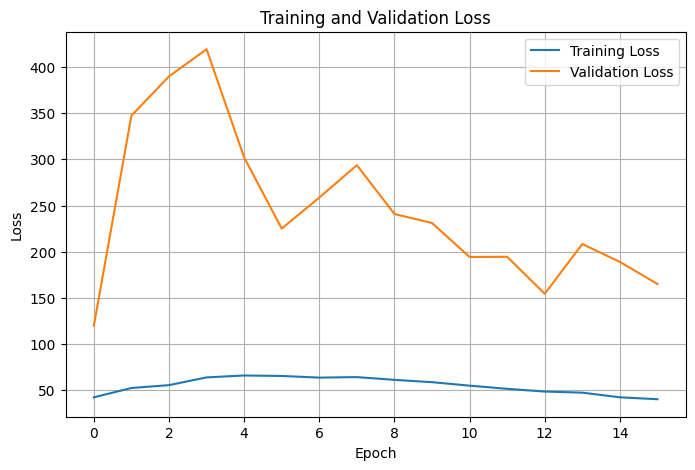

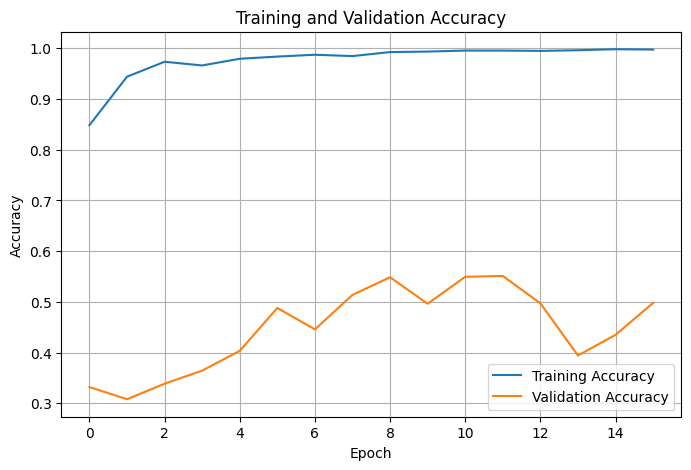

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(history.history.get("loss", []), label="Training Loss")
plt.plot(history.history.get("val_loss", []), label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history.get("accuracy", []), label="Training Accuracy")
plt.plot(history.history.get("val_accuracy", []), label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## Testing

This evaluates every held-out test segment selected by the `File_Name` split.

In [33]:
print("Number of test samples being evaluated:", X_test.shape[0])
print("Test class distribution:")
print(pd.Series(y_test).value_counts())

if X_test.shape[0] == 0:
    raise ValueError("No test samples were selected. Increase dataset size or adjust TEST_SUBJECTS_PER_CLASS / manual test_folders.")

test_loss, test_accuracy = model.evaluate(X_test_inputs, y_test_one_hot, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

y_test_prob = model.predict(X_test_inputs)
y_test_pred_encoded = np.argmax(y_test_prob, axis=1)
y_test_pred = label_encoder.inverse_transform(y_test_pred_encoded)

print("\nClassification report:")
print(classification_report(y_test, y_test_pred, labels=label_encoder.classes_, zero_division=0))


Number of test samples being evaluated: 1216
Test class distribution:
abnormal      440
normal        391
borderline    385
Name: count, dtype: int64
Test loss: 314.4557800292969
Test accuracy: 0.3815789520740509
38/38 [==============================] - 24s 615ms/step

Classification report:
              precision    recall  f1-score   support

    abnormal       0.41      0.71      0.52       440
  borderline       0.00      0.00      0.00       385
      normal       0.35      0.39      0.37       391

    accuracy                           0.38      1216
   macro avg       0.25      0.37      0.30      1216
weighted avg       0.26      0.38      0.31      1216



## Confusion Matrix

<Figure size 700x600 with 0 Axes>

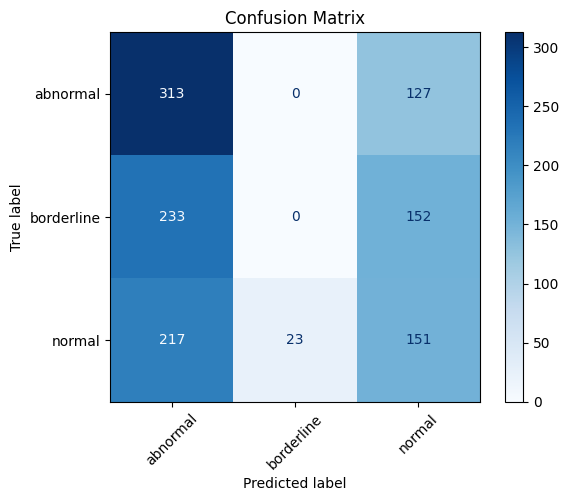

In [34]:
cm = confusion_matrix(y_test, y_test_pred, labels=label_encoder.classes_)

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.show()


## ROC/AUC

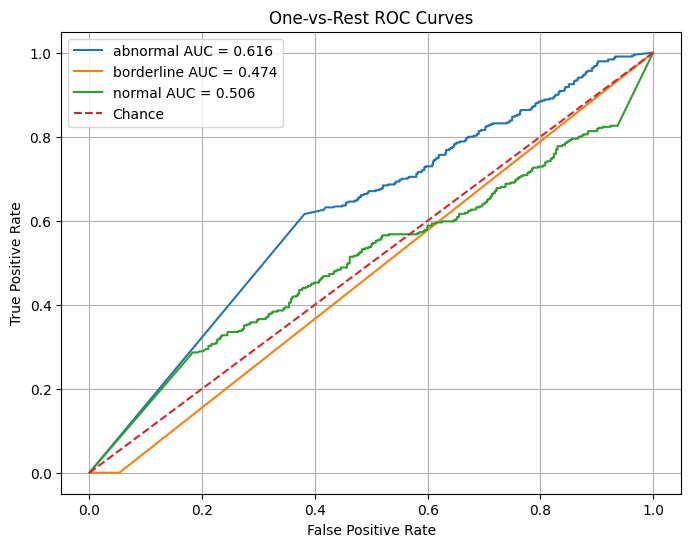

In [35]:
plt.figure(figsize=(8, 6))

for class_index, class_name in enumerate(label_encoder.classes_):
    y_true_binary = y_test_one_hot[:, class_index]

    # ROC requires both positive and negative examples for the class.
    if len(np.unique(y_true_binary)) < 2:
        print(f"Skipping ROC for {class_name}: test set does not contain both positive and negative examples.")
        continue

    fpr, tpr, _ = roc_curve(y_true_binary, y_test_prob[:, class_index])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} AUC = {roc_auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend()
plt.grid(True)
plt.show()


## F1 Score

In [36]:
macro_f1 = f1_score(y_test, y_test_pred, labels=label_encoder.classes_, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_test_pred, labels=label_encoder.classes_, average="weighted", zero_division=0)

print("Macro F1:", macro_f1)
print("Weighted F1:", weighted_f1)


Macro F1: 0.29606994828532945
Weighted F1: 0.30656905526373607


## Save Outputs

In [37]:
# Save useful outputs for later analysis.
results_pickle_file = "three_excel_multi_head_cnn_results.pickle"

results = {
    "active_signal_columns": active_signal_columns,
    "IDEAL_LENGTH": IDEAL_LENGTH,
    "PADDING_MODE": PADDING_MODE,
    "label_classes": label_encoder.classes_.tolist(),
    "test_folders": test_folders,
    "validation_folders": validation_folders,
    "sample_meta_df": sample_meta_df,
    "train_meta_df": train_meta_df,
    "valid_meta_df": valid_meta_df,
    "test_meta_df": test_meta_df,
    "history": history.history,
    "y_test": y_test,
    "y_test_pred": y_test_pred,
    "y_test_prob": y_test_prob,
}

with open(results_pickle_file, "wb") as f:
    pickle.dump(results, f)

print("Saved results to:", results_pickle_file)
print("Saved best model to: best_multi_head_ecg_model.keras")


Saved results to: three_excel_multi_head_cnn_results.pickle
Saved best model to: best_multi_head_ecg_model.keras
